In [150]:
import pandas as pd
import numpy as np
import json
import rapidfuzz
from random import choice
from matplotlib import pyplot as plt
import seaborn as sns

## Loading data

In [151]:
events_json = (
    "outputs/json/all_migration_events_parish_splits/"
    "395_migration_events.jsonl"
)

with open(events_json, "r") as fp:
    lines = list(
        json.loads(json_line)
        for json_line in fp
    )

In [152]:
print_columns_df = pd.read_csv("outputs/csv/print_type_columns.csv")
print_columns_df = print_columns_df.rename(
    {"print type": "print_type", "sarakkeet": "column"}, axis="columns"
)
print_columns_df["column"] = print_columns_df["column"].apply(
    lambda cols: json.loads(cols.replace("'", '"'))
)
print_columns_df = print_columns_df.explode("column").reset_index(drop=True)

In [153]:
print_columns_df["column_idx"] = print_columns_df.groupby("print_type").cumcount()

In [154]:
with open("outputs/json/print_type_column_names_categorized.json", "r") as fp:
    print_column_name_to_categorized = json.load(fp)

In [155]:
print_columns_df["column_categorized"] = print_columns_df["column"].apply(
    print_column_name_to_categorized.get
)

## Finding toponym columns

Idea: search cell strings from list of toponyms. Columns that contain toponyms
should have the best matches.

In [156]:
chosen_page = list(
    filter(
        lambda x: (
            x["page_n"] == 1
            and x["side"] == "left"
            and x["book"] == "pielavesi_muuttaneet_1881-1887_mko44-45"
        ),
        lines
    )
)

page_data = []
for row in chosen_page:
    page_data.append(row["row_data"])
    prev_page = row["page_n"]

In [157]:
def transpose_page_table(page_data):
    page_cols = []
    for col in range(len(page_data[0])):
        page_cols.append(
            [
                row[col] if len(row) > col else ""
                for row in page_data
            ]
        )
    return page_cols

page_cols = transpose_page_table(page_data)

In [158]:
with open("data/kohde_split.txt", "r") as fp:
    valid_toponyms = set(toponym.replace("\n", "") for toponym in fp.readlines())

with open("outputs/json/db_toponyms.json", "r") as fp:
    valid_toponyms = valid_toponyms.union(
        set(json.load(fp).keys())
    )

In [159]:
def column_match_scores(
    column,
    choices,
    scorer=rapidfuzz.distance.JaroWinkler.normalized_similarity,
    return_scores_only=True,
):
    column_match_scores = []
    for cell in column:
        cell_score = rapidfuzz.process.extractOne(
            cell,
            choices,
            scorer=scorer,
        )

        column_match_scores.append(
            cell_score[1] if return_scores_only else cell_score
        )

    return column_match_scores

In [160]:
columns_toponym_scores = [
    column_match_scores(col, valid_toponyms)
    for col in page_cols
]
column_average_scores = [np.mean(col) for col in columns_toponym_scores]
print(np.argmax(column_average_scores))
display(page_cols[np.argmax(column_average_scores)][:5])

3


['Poika Johanna Watanen',
 'Erika Tikkanen',
 'Työm:poika Paavo Ruotsalainen',
 'Talontr. Wiljolmiä Räisänen',
 'Renki Petter Auvinen']

In [161]:
print_columns_df[print_columns_df["print_type"] == f"print {chosen_page[0]["print_type"]}"].set_index(
    "column_idx"
)[["column", "column_categorized"]]

,column,column_categorized
column_idx,,
0,kuukausi,other
1,päivä,other
2,muuttokirjan numero,other
3,nimi ja sääty,name
4,miespuoli,person_count
5,naispuoli,person_count
6,(syntymä)päivä,other
7,(syntymä)paikka,place
8,empty,


Index 7 is the place a person was born in and index 10 is the place the person
moved to (column 8 "empty" doesn't exist in csv data).

Would expect index 7 or 10. The process is maybe thrown off by empty values:

In [162]:
print(*page_data[:5], sep="\n")

['Tammikuun', '2.', '1.', 'Poika Johanna Watanen', '', '1.', '30/5 1862', 'Pielavalellä', 'Naimaton', 'Työnteko', 'Kuopioon', '301.', 'Hyvämäininen.']
['', '3.', '2', 'Erika Tikkanen', '', '1', '1863.', '', '', '1', 'Määnika', '459.459', '']
['', '4', '3.', 'Työm:poika Paavo Ruotsalainen', '1.', '', '1864', '', '', '', 'Kuopioon', '955 L', '']
['', '9.', '4.', 'Talontr. Wiljolmiä Räisänen', '-', '1.', '1862.', '1o', '', '', '1o', '691.', '']
['', '11', '5.', 'Renki Petter Auvinen', '1', '', '1852.', '', '', '', '', '670.', 'Sakertettu viinan myönnistä']


It's likely that the empty values here mean that the previous value should be
repeated, at least for dates and placenames.

In [163]:
def fill_empty_values(column):
    filled_cells = []
    for i, cell in enumerate(column):
        if cell != "":
            filled_cells.append(cell)
        elif len(filled_cells) != 0:
            filled_cells.append(filled_cells[i - 1])
        else:
            filled_cells.append("")

    return filled_cells

In [164]:
levenshtein_scorer = rapidfuzz.distance.Levenshtein.normalized_similarity
jarowinkler_scorer = rapidfuzz.distance.JaroWinkler.normalized_similarity

columns_toponym_scores_levenshtein = [
    column_match_scores(
        fill_empty_values(col), valid_toponyms, scorer=levenshtein_scorer
    )
    for col in page_cols
]
columns_toponym_scores_jarowinkler = [
    column_match_scores(
        fill_empty_values(col), valid_toponyms, scorer=jarowinkler_scorer
    )
    for col in page_cols
]

column_average_scores_levenshtein = [
    np.mean(col) for col in columns_toponym_scores_levenshtein
]
column_average_scores_jarowinkler = [
    np.mean(col) for col in columns_toponym_scores_jarowinkler
]

With Levenshtein: [10 12  7  8  0  9  3  1  2 11  5  4  6]
With Jaro-Winkler: [10  7  0 12  9  8  5  3  4  2  1 11  6]


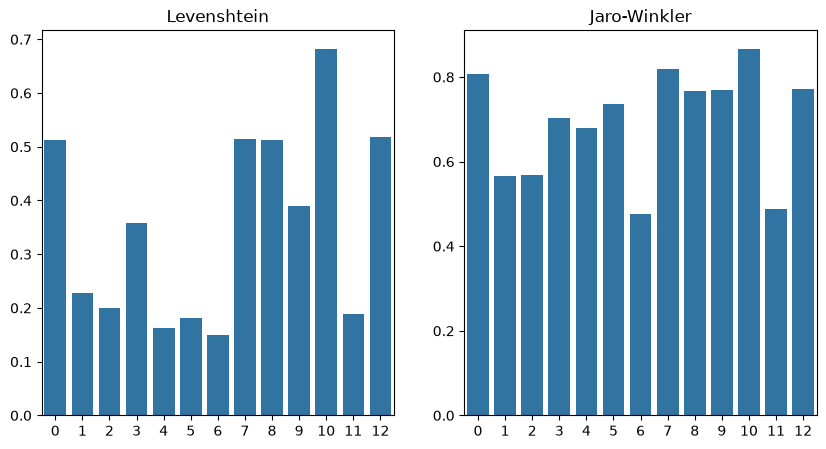

In [165]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
sns.barplot(column_average_scores_levenshtein, ax=axs[0])
sns.barplot(column_average_scores_jarowinkler, ax=axs[1])

axs[0].set_title("Levenshtein")
axs[1].set_title("Jaro-Winkler")

print("With Levenshtein:", np.argsort(column_average_scores_levenshtein)[::-1])
print("With Jaro-Winkler:", np.argsort(column_average_scores_jarowinkler)[::-1])

The Levenshtein seems to be the better metric to use here since it gives
a bigger difference between the toponym columns and the others.

Now the column at index 10 is correctly detected as place name column, but the
next best column should be 7, not 12 and columns 8 and 0 are uncomfortably close to the correct ones.:

In [166]:
print("index 0", list(filter(bool, page_cols[0])))
print("index 7", list(filter(bool, page_cols[7])))
print("index 8", list(filter(bool, page_cols[8])))
print("index 10", list(filter(bool, page_cols[10])))
print("index 12", list(filter(bool, page_cols[12])))

index 0 ['Tammikuun', 'Helmikuu', 'Maaliskun']
index 7 ['Pielavalellä', '1o', 'Iisalmella', 'Pielavedellä']
index 8 ['Naimaton', 'nainut.', 'naimaton', 'Nainut', 'Leski', 'Naimaton', 'Nainut', 'naimaton', 'nainut', 'Naimaton', 'Leski', 'Naimit.', 'Naimaton', 'Nainut', 'Naimaton']
index 10 ['Kuopioon', 'Määnika', 'Kuopioon', '1o', 'Kuinvedell', 'pajunis', 'Maaniska', 'Iisalmalle', 'Heipinkiin', 'Lappeenanta', 'Maaniska', 'Kuopioon', 'Maaniska', 'Pihlajavesi', 'Kunnvesi', 'Iisalmeen', 'Kuopio', 'Pykäjänä', 'Kunnonsi']
index 12 ['Hyvämäininen.', 'Sakertettu viinan myönnistä', 'Kunniallinen.']


### Numerical / text column differentiation

In [167]:
def column_numeric_ratio(column):
    all_text = "".join(column)
    all_text_len = len(all_text)
    if all_text_len == 0:
        return 0.0
    n_of_numeric_chars = list(map(str.isnumeric, all_text)).count(True)

    return n_of_numeric_chars / all_text_len

def column_alpha_ratio(column):
    all_text = "".join(column)
    all_text_len = len(all_text)
    if all_text_len == 0:
        return 0.0
    n_of_alpha_chars = list(map(str.isalpha, all_text)).count(True)

    return n_of_alpha_chars / all_text_len

Text(0.5, 1.0, 'Alphabetic')

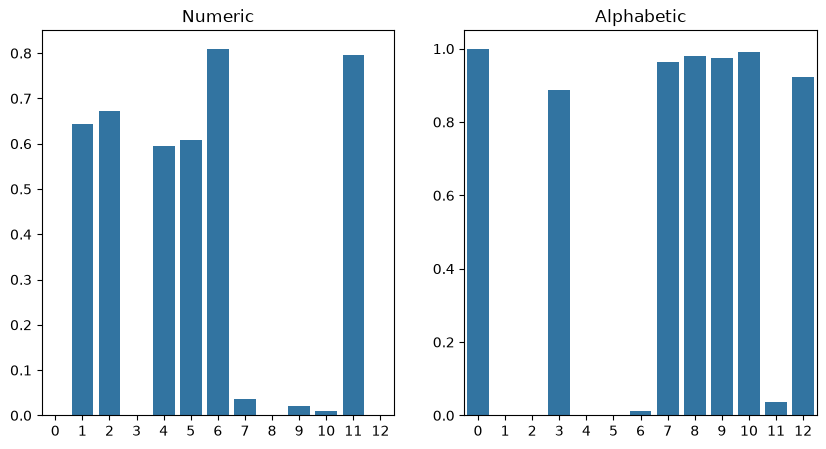

In [168]:
column_numeric_ratios = [
    column_numeric_ratio(fill_empty_values(col)) for col in page_cols
]
column_alpha_ratios = [
    column_alpha_ratio(fill_empty_values(col)) for col in page_cols
]

fig, axs = plt.subplots(1, 2, figsize=(10, 5))
sns.barplot(column_numeric_ratios, ax=axs[0])
sns.barplot(column_alpha_ratios, ax=axs[1])

axs[0].set_title("Numeric")
axs[1].set_title("Alphabetic")

This is unfortunately correlated with the previous metric and therefore not
useful:

In [169]:
from scipy.stats import spearmanr
result_num_ratio = spearmanr(
    column_average_scores_levenshtein,
    column_numeric_ratios,
)
result_alp_ratio = spearmanr(
    column_average_scores_levenshtein,
    column_alpha_ratios,
)
print(
    result_num_ratio.statistic,
    result_num_ratio.pvalue
)
print(
    result_alp_ratio.statistic,
    result_alp_ratio.pvalue
)

-0.74101894915541 0.0037541026282404905
0.7744483754330976 0.0018829611866818725


### Checking for column with people's names

In [170]:
with open("data/etunimi_split.txt", "r") as fp:
    valid_first_names = set(name.replace("\n", "") for name in fp.readlines())

with open("data/sukunimi_split.txt", "r") as fp:
    valid_last_names = set(name.replace("\n", "") for name in fp.readlines())
with open("data/patron_split.txt", "r") as fp:
    valid_patronyms = set(name.replace("\n", "") for name in fp.readlines())

In [171]:
column_match_scores(
    fill_empty_values(page_cols[3]), valid_first_names, scorer=levenshtein_scorer,
    return_scores_only=False
)

[('Johannan', 0.38095238095238093, 2214),
 ('Eriikka', 0.5, 2885),
 ('Pauline', 0.24137931034482762, 764),
 ('Wilhelmine', 0.2962962962962963, 571),
 ('Henriette', 0.35, 508),
 ('Alekasandra', 0.3157894736842105, 6375),
 ('Friedericha', 0.2666666666666667, 1426),
 ('Hinriette', 0.21212121212121215, 137),
 ('Petrolina', 0.30000000000000004, 334),
 ('Vilhelm', 0.5, 895),
 ('Rikartti', 0.368421052631579, 1214),
 ('Tobian', 0.24, 214),
 ('Caitarina', 0.30000000000000004, 149),
 ('Maria-Elisabet', 0.2857142857142857, 915),
 ('Constantina', 0.25, 272),
 ('Björn', 0.5, 1601),
 ('Rikaartti', 0.38888888888888884, 2714),
 ('Elisabetta', 0.2692307692307693, 1418),
 ('Valdine', 0.2692307692307693, 539),
 ('Polikarpus', 0.4545454545454546, 601),
 ('Hentriikka', 0.21875, 483),
 ('Josefine', 0.36363636363636365, 1178),
 ('Maijalovisa', 0.29166666666666663, 3256),
 ('Lennart', 0.28, 64),
 ('Kristina', 0.34782608695652173, 793),
 ('Gustaviana', 0.3076923076923077, 4961),
 ('Maria-Elisabet', 0.258064516

Text(0.5, 1.0, 'Patronym')

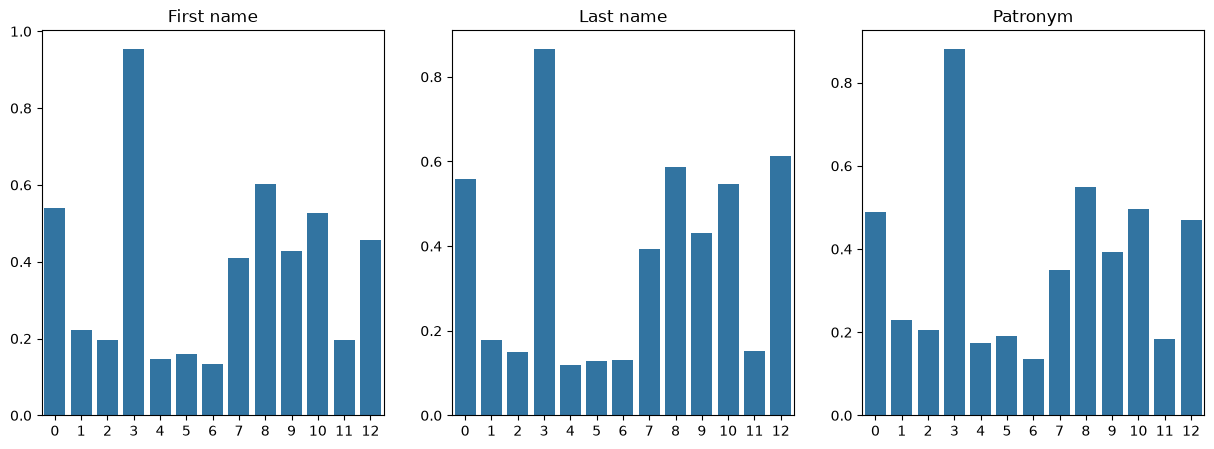

In [172]:
def partial_ratio_scorer(a, b, score_cutoff=0):
    if min(len(a), len(b)) == 0:
        return 0.0
    else:
        return max(
            levenshtein_scorer(candidate, b)
            for candidate in a.split(" ")
        )

columns_fname_scores_levenshtein = [
    column_match_scores(
        fill_empty_values(col), valid_first_names, scorer=partial_ratio_scorer
    )
    for col in page_cols
]
columns_lname_scores_levenshtein = [
    column_match_scores(
        fill_empty_values(col), valid_last_names, scorer=partial_ratio_scorer
    )
    for col in page_cols
]
columns_pnym_scores_levenshtein = [
    column_match_scores(
        fill_empty_values(col), valid_patronyms, scorer=partial_ratio_scorer
    )
    for col in page_cols
]


fig, axs = plt.subplots(1, 3, figsize=(15, 5))
sns.barplot([np.mean(x) for x in columns_fname_scores_levenshtein], ax=axs[0])
sns.barplot([np.mean(x) for x in columns_lname_scores_levenshtein], ax=axs[1])
sns.barplot([np.mean(x) for x in columns_pnym_scores_levenshtein], ax=axs[2])

axs[0].set_title("First name")
axs[1].set_title("Last name")
axs[2].set_title("Patronym")

<Axes: >

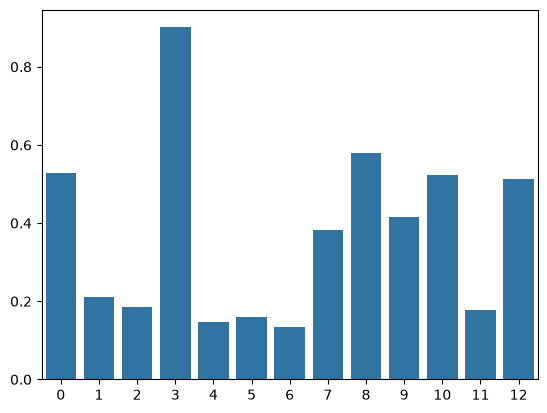

In [173]:
combined_names = (
    np.array([np.mean(x) for x in columns_fname_scores_levenshtein])
    + np.array([np.mean(x) for x in columns_lname_scores_levenshtein])
    + np.array([np.mean(x) for x in columns_pnym_scores_levenshtein])
) / 3

sns.barplot(combined_names)

In [174]:
result_combined_names = spearmanr(
    column_average_scores_levenshtein,
    combined_names,
)
print(
    result_combined_names.statistic,
    result_combined_names.pvalue
)

0.7857142857142857 0.0014541896038438233


This too is maybe not very useful for ruling out columns when trying to find
toponym column.

## Testing with random pages

In [175]:
books = set(x["book"] for x in lines)
book_and_p = [
    (
        book,
        choice(
            list(set(
                y["page_n"]
                for y in filter(lambda x: x["book"] == book, lines)
            ))
        ),
    )
    for book in books
]

In [176]:
for book in books:
    print(set(e["side"] for e in (filter(lambda x: x["book"] == book, lines))))

{'left', 'right'}
{'left'}
{'left'}
{'left', 'right'}
{'left', 'right'}
{'left'}
{'left', 'right'}


In [177]:
chosen_pages = [
    list(
        filter(
            lambda x: x["book"] == book,
            lines,
        )
    )
    for book, page_n in book_and_p
]

In [178]:
chosen_pages = [
    list(
        filter(
            lambda x: (x["page_n"] == page_n and x["book"] == book),
            lines,
        )
    )
    for book, page_n in book_and_p
]

chosen_pages_data = []
for page in chosen_pages:
    chosen_pages_data.append([row["row_data"] for row in page])

chosen_pages_cols = [
    transpose_page_table(page_data) for page_data in chosen_pages_data
]

In [179]:
levenshtein_scorer = rapidfuzz.distance.Levenshtein.normalized_similarity

page_results = []
for page_cols in chosen_pages_cols:
    columns_toponym_scores_levenshtein = [
        column_match_scores(
            fill_empty_values(col), valid_toponyms, scorer=levenshtein_scorer
        )
        for col in page_cols
    ]
    column_average_scores_levenshtein = [
        np.mean(col) for col in columns_toponym_scores_levenshtein
    ]
    page_results.append(column_average_scores_levenshtein)
    toponym_col_idx = np.argmax(column_average_scores_levenshtein)
    print(
        "With Levenshtein: column",
        toponym_col_idx,
        "with score",
        column_average_scores_levenshtein[toponym_col_idx],
    )
    print(*filter(bool, page_cols[toponym_col_idx]))
    print("---")

With Levenshtein: column 5 with score 0.8253576801449143
Iisalmi Kihnimi Lapinlahti Mauninka Kiuruvesi Maunika Ulenborg Kuopio Kerttula Kuopio Pyhäjärvi Maaniska Karttula Suomajoki Karttula Transport Iisalmi 1 Kuopio 1 Pihtipudas 1 Wipurin kaupunf. 1 Maaniska 1 Lapinlahti 1 Iisalmelle 1 Tuusniemelle Kimmanalle Maaniska Iisalmi Wiborg Joutsme Maunikka Transint 14
---
With Levenshtein: column 7 with score 0.9645833333333333
Pielavesi Lapinlahti Pielavesi Kuopio Tyrnävä Pielavesi Kiivruvesi Pielavesi Kiuruvesi Kartinto Nastola Pielavesi Helinki Pihtipudas Kuopio Helsinki Lapua Kiuravesi
---
With Levenshtein: column 7 with score 0.9258078231292517
Piehvesi Keitele Pielavesi Karttala Pielavesi Kiuruvesi Pielavesi
---
With Levenshtein: column 5 with score 0.8202020202020203
Pieluomi Pihtipudas
---
With Levenshtein: column 11 with score 0.9163548752834468
nissä Maaniska Leppavita. Kuopio Kiuruvesi Karttula Kiuruvesi Wiipuri Helsinki Rautalampi Iisalmi Kuopio Kalajoki Iisalmi Wiitajani Wanaja 

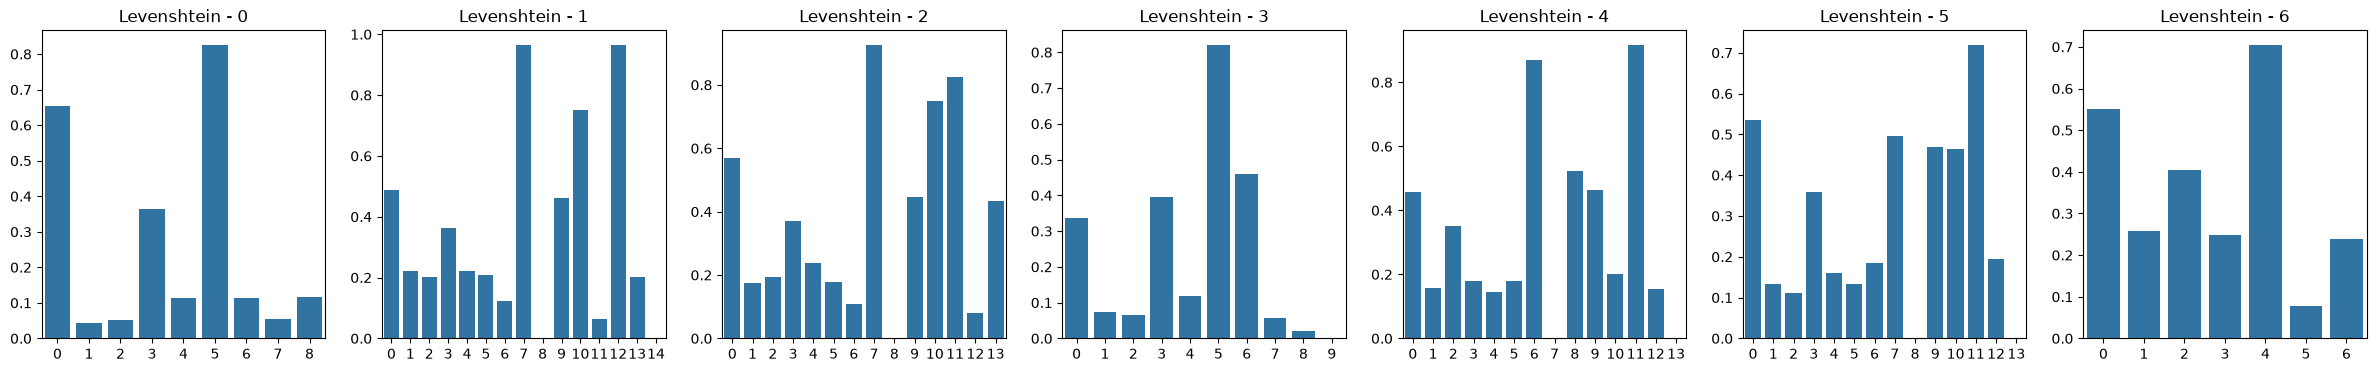

In [180]:
fig, axs = plt.subplots(1, 7, figsize=(30, 4))
for i, (ax, res) in enumerate(zip(axs, page_results)):
    sns.barplot(res, ax=ax)
    ax.set_title(f"Levenshtein - {i}")

['Saarela', '1', '', 'Bag. hn Johanna Emilia Roslan', '19/12 79', 'Iisalmi', '', '1', '16/12 1855']


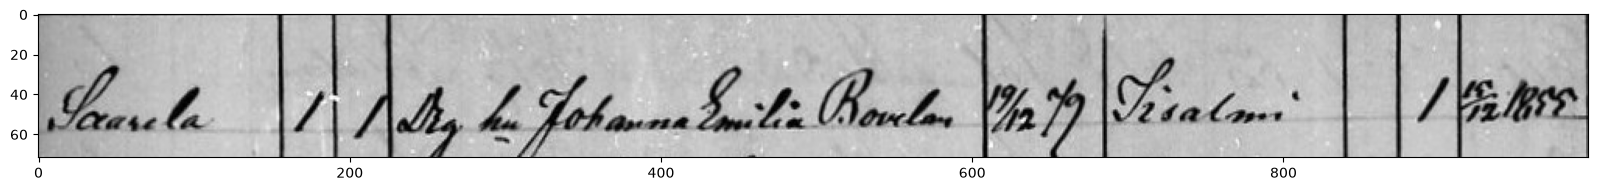

In [181]:
from collections import defaultdict
from pathlib import Path
from bs4 import BeautifulSoup
import cv2
from src.xml_image_coordinates import get_cell_coords, get_left_right_xml_tables, get_single_img_path, get_single_xml_path

row = 0
xml_path = get_single_xml_path(Path(chosen_pages[0][row]["file_path"]).stem, Path("data/xml"))
img_path = get_single_img_path(Path(chosen_pages[0][row]["file_path"]).stem, Path("data/xml"))

with open(xml_path, "r") as fp:
    xml = BeautifulSoup(fp.read(), features="xml")

left_table, right_table = get_left_right_xml_tables(xml)
left_table_rows = defaultdict(list)
for cell in left_table.find_all("TableCell"):
    left_table_rows[int(cell["row"])].append(cell)

row_text = chosen_pages[0][row]["row_data"]
print(row_text)

img = cv2.imread(img_path, cv2.IMREAD_COLOR_RGB)
x0, y0 = get_cell_coords(left_table_rows[row][0])[0]
x1, y1 = get_cell_coords(left_table_rows[row][-1])[2]
img_cropped = img[y0:y1, x0:x1]
aspect_ratio = (img.shape[1] / img.shape[0])
fig, axs = plt.subplots(1, 1, figsize=(20, 10))
plt.imshow(img_cropped, aspect=aspect_ratio)

In [182]:
chosen_pages[0]

[{'row_data': ['Saarela',
   '1',
   '',
   'Bag. hn Johanna Emilia Roslan',
   '19/12 79',
   'Iisalmi',
   '',
   '1',
   '16/12 1855'],
  'row_columns': [],
  'row_columns_categorized': [],
  'year_prediction': 1880,
  'possible_name': None,
  'possibly_related_toponym': [],
  'file_path': 'data/migration-data-csv-release-v1/pielavesi/muuttaneet_1875-1880_mko6/autods_pielavesi_muuttaneet_1875-1880_mko6_20_left_5.csv',
  'parish_id': 395,
  'book': 'pielavesi_muuttaneet_1875-1880_mko6',
  'print_type': nan,
  'book_source': 'mko6',
  'book_year_start': '1875',
  'book_year_end': '1880',
  'image_range_start': '1',
  'image_range_end': '24',
  'page_n': 20,
  'file_row': 0,
  'in/out': 'in',
  'side': 'left',
  'has_information': True},
 {'row_data': ['Rytky',
   '3',
   '2',
   'bn dott Stina Kärkkäinen',
   '11/180',
   'Kihnimi',
   '',
   '1',
   '24/4 1860'],
  'row_columns': [],
  'row_columns_categorized': [],
  'year_prediction': 1880,
  'possible_name': None,
  'possibly_rela

## Extract multiple placenames

In [183]:
levenshtein_scorer = rapidfuzz.distance.Levenshtein.normalized_similarity

page_results = []
for page_i, page_cols in enumerate(chosen_pages_cols):
    print(page_cols)
    columns_toponym_scores_levenshtein = [
        column_match_scores(
            fill_empty_values(col), valid_toponyms, scorer=levenshtein_scorer
        )
        for col in page_cols
    ]
    column_average_scores_levenshtein = [
        np.mean(col) for col in columns_toponym_scores_levenshtein
    ]
    page_results.append(column_average_scores_levenshtein)

np.argsort(page_results[2])[::-1]

[['Saarela', 'Rytky', 'Jylänki', 'Pielammi', 'Haatola', '', 'Tommonmäki', 'Past.balet', 'Pielammi', 'Hautala', 'Utrianlahti', '', 'Jautuniemi', 'Saarila', 'Taum', '', 'Koivulahti', '', 'Taumo', 'Kainulahti', 'Fallus K', 'Kuinaniemi', '', 'LampaanjärviLampamjärvi', 'Rytky', 'Lankkala', 'Koianjärvi', 'Leväniemi', 'Lampaanjärvi', 'Tuovilankt', 'Löytyömäki', 'Lampamjärvi', 'LappetilaSappetila', 'huovilautahtiSuovilanlahti', '', 'Lampainjärvi', 'JylkaLylka', 'Laikkala', 'Wauraslahti', 'TallusTallus', 'Leppämäki', '', '', '', '', '', ''], ['1', '3', '1', '8', '9', '', '3', '', '7', '6', '2', '5', '8', '1', '4', '5', '2', '', '1', '1', '2', '1', '', '22', '2', '1', '3', '1', '18', '10', '', '9', '1', '', '', '15', '-', '2', '-', '6', '1', '', '', '', '', '', ''], ['', '2', '3', '4', '5', '6', '7', '8', '9', 'III', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '', ''

array([ 7, 11, 10,  0,  9, 13,  3,  4,  2,  5,  1,  6, 12,  8])

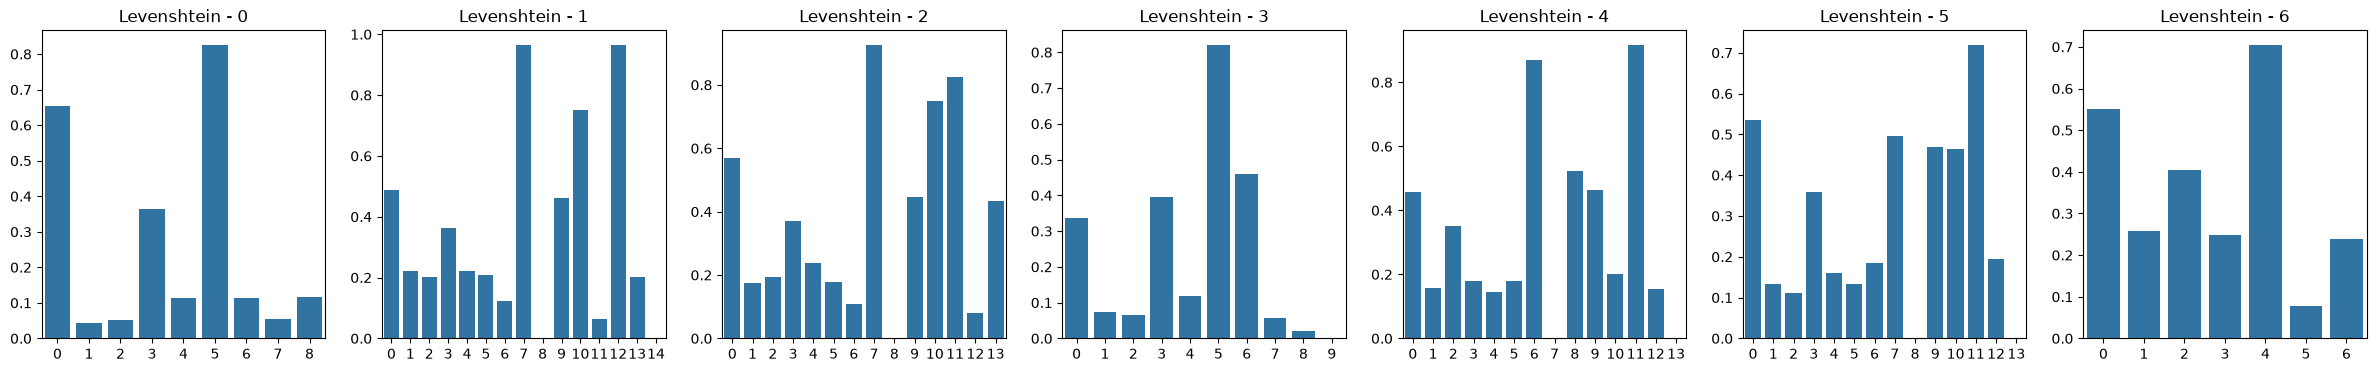

In [184]:
fig, axs = plt.subplots(1, 7, figsize=(30, 4))
for i, (ax, res) in enumerate(zip(axs, page_results)):
    sns.barplot(res, ax=ax)
    ax.set_title(f"Levenshtein - {i}")

In [185]:
chosen_pages[1][0]

{'row_data': ['Heinäkuu',
  '4.',
  '60.',
  'Ompel. Silja Westerinen',
  '',
  '1',
  '22/10 81',
  'Pielavesi',
  '',
  'nton',
  'Työ',
  '22/6 03',
  'Helsinki',
  '295.',
  ''],
 'row_columns': ['kuukausi',
  'päivä',
  'nimi ja sääty',
  'miespuoli',
  'naispuoli',
  '(syntymä)päivä',
  '(syntymä)paikka',
  'empty',
  'leski, nainut, naimaton',
  'elatuskeino',
  '(muuttokirjan)päivä',
  '(muuttokirjan)paikka',
  'lehti kirkonkirjasta',
  'muistutuksia'],
 'row_columns_categorized': ['other',
  'other',
  'name',
  'person_count',
  'person_count',
  'other',
  'place',
  '',
  'other',
  'other',
  'other',
  'place',
  'other',
  'other'],
 'year_prediction': 1888,
 'possible_name': '60.',
 'possibly_related_toponym': [[6, '22/10 81', 'place'],
  [11, '22/6 03', 'place']],
 'file_path': 'data/migration-data-csv-release-v1/pielavesi/muuttaneet_1888-1904_mko7-11/autods_pielavesi_muuttaneet_1888-1904_mko7-11_94_left_3.csv',
 'parish_id': 395,
 'book': 'pielavesi_muuttaneet_1888-19

In [197]:
chosen_pages[1][0]["possibly_related_toponym"]
print(
    np.argsort(page_results[1])[::-1][:2],
    [x[2] for x in chosen_pages[1][0]["possibly_related_toponym"]],
    sep="\n"
)

[ 7 12]
['place', 'place']
